In [2]:

# MOBILE PHONE PRICE ANALYSIS
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload the cleaned dataset
uploaded = files.upload()
file_name = next(iter(uploaded))

# Read dataset
df = pd.read_csv(file_name)

# Display dataset
print("First 5 records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Saving mobile_phone_price_cleaned.csv to mobile_phone_price_cleaned (1).csv
First 5 records:


,phone_id,brand,model,ram_gb,storage_gb,battery_mah,camera_mp,release_year,price_inr
0,MP001,Oppo,A58,4,256,4500,50,2022,29488
1,MP002,Xiaomi,Xiaomi 13T,12,256,5500,108,2022,27011
2,MP003,Samsung,Galaxy A35,4,512,5000,200,2023,30763
3,MP004,Vivo,Y27,8,256,5500,64,2023,32783
4,MP005,Apple,Iphone 14,4,64,5500,64,2022,57830



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   phone_id      120 non-null    object
 1   brand         120 non-null    object
 2   model         120 non-null    object
 3   ram_gb        120 non-null    int64 
 4   storage_gb    120 non-null    int64 
 5   battery_mah   120 non-null    int64 
 6   camera_mp     120 non-null    int64 
 7   release_year  120 non-null    int64 
 8   price_inr     120 non-null    int64 
dtypes: int64(6), object(3)
memory usage: 8.6+ KB

Statistical Summary:


,ram_gb,storage_gb,battery_mah,camera_mp,release_year,price_inr
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,8.216667,227.200000,4820.833333,81.250000,2023.516667,33935.941667
std,4.015063,168.788546,564.331364,59.564844,1.084523,11452.731663
min,4.000000,64.000000,4000.000000,12.000000,2022.000000,13876.000000
25%,5.500000,64.000000,4500.000000,48.000000,2023.000000,26822.500000
50%,8.000000,128.000000,5000.000000,50.000000,2023.000000,31707.000000
75%,12.000000,256.000000,5500.000000,108.000000,2024.250000,39225.500000
max,16.000000,512.000000,5500.000000,200.000000,2025.000000,57830.000000



Missing Values:
phone_id        0
brand           0
model           0
ram_gb          0
storage_gb      0
battery_mah     0
camera_mp       0
release_year    0
price_inr       0
dtype: int64


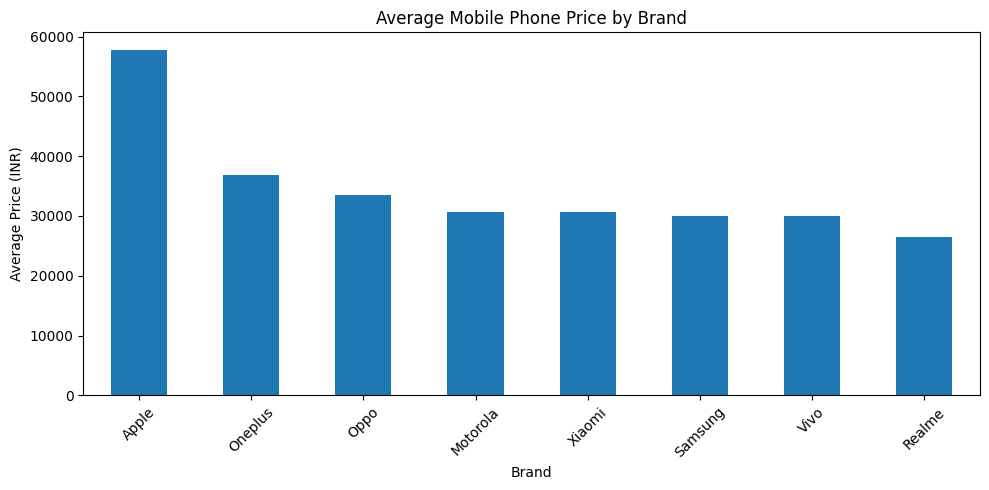

In [3]:
brand_price = df.groupby("brand")["price_inr"].mean()
brand_price = brand_price.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
brand_price.plot(kind="bar")

plt.title("Average Mobile Phone Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

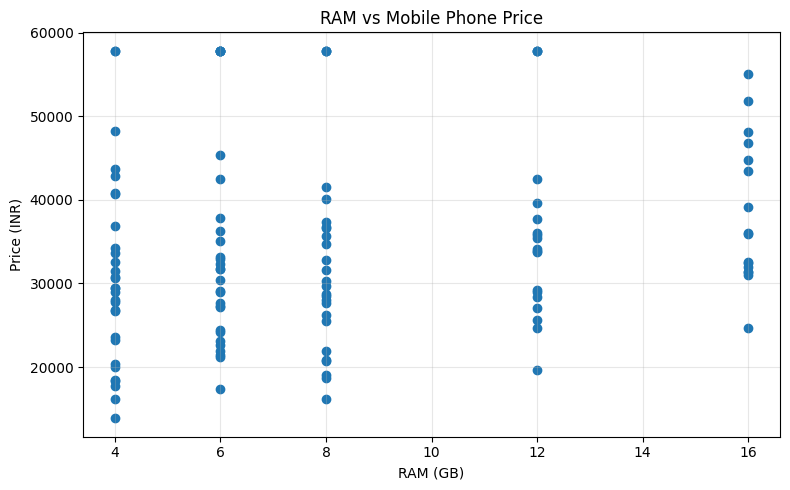

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(df["ram_gb"], df["price_inr"])

plt.title("RAM vs Mobile Phone Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (INR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

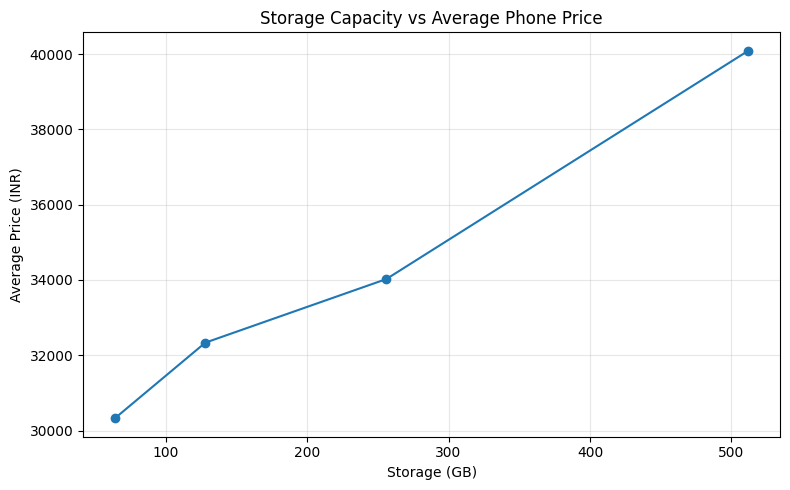

In [5]:
storage_price = df.groupby("storage_gb")["price_inr"].mean()

plt.figure(figsize=(8, 5))
plt.plot(storage_price.index, storage_price.values, marker="o")

plt.title("Storage Capacity vs Average Phone Price")
plt.xlabel("Storage (GB)")
plt.ylabel("Average Price (INR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

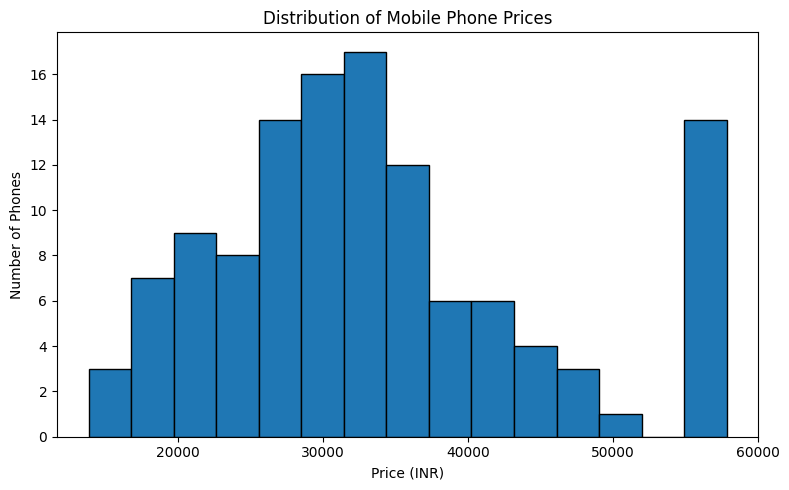

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["price_inr"], bins=15, edgecolor="black")

plt.title("Distribution of Mobile Phone Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Phones")
plt.tight_layout()
plt.show()

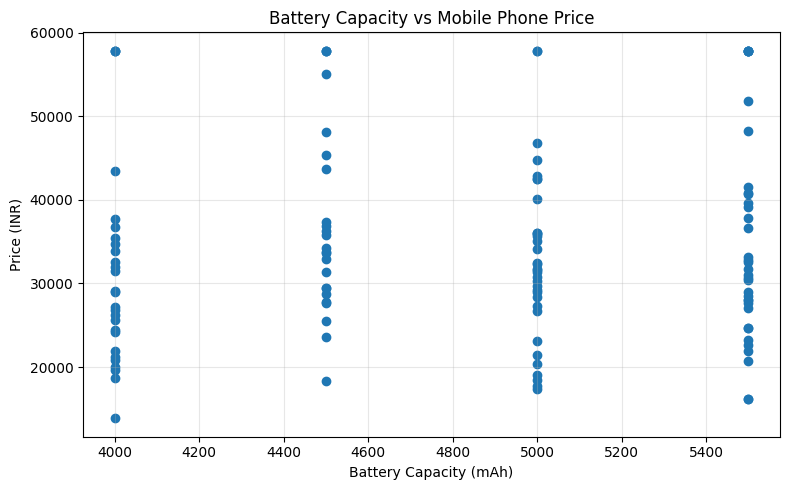

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(df["battery_mah"], df["price_inr"])

plt.title("Battery Capacity vs Mobile Phone Price")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Price (INR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

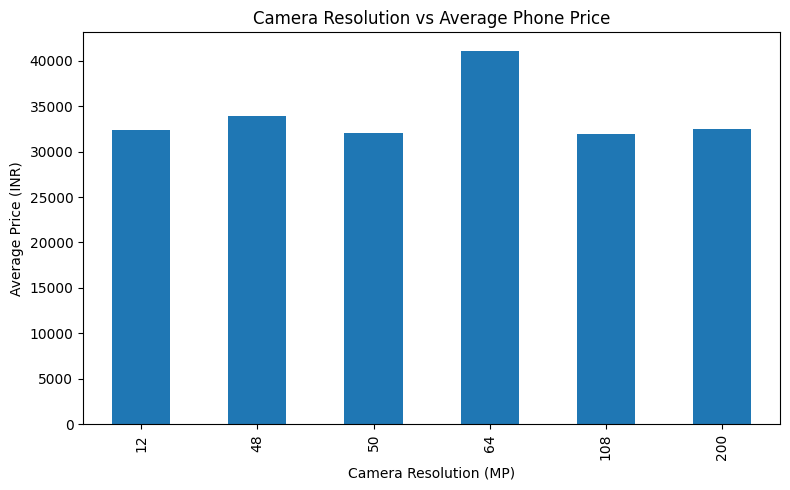

In [8]:
camera_price = df.groupby("camera_mp")["price_inr"].mean()

plt.figure(figsize=(8, 5))
camera_price.plot(kind="bar")

plt.title("Camera Resolution vs Average Phone Price")
plt.xlabel("Camera Resolution (MP)")
plt.ylabel("Average Price (INR)")
plt.tight_layout()
plt.show()

In [9]:
print("MOBILE PHONE PRICE ANALYSIS")
print("---------------------------")

print("Total mobile phones:", len(df))
print("Number of brands:", df["brand"].nunique())
print("Minimum price: ₹", df["price_inr"].min())
print("Maximum price: ₹", df["price_inr"].max())
print("Average price: ₹", round(df["price_inr"].mean(), 2))

print("\nAverage Price by Brand:")
print(
    df.groupby("brand")["price_inr"]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

MOBILE PHONE PRICE ANALYSIS
---------------------------
Total mobile phones: 120
Number of brands: 8
Minimum price: ₹ 13876
Maximum price: ₹ 57830
Average price: ₹ 33935.94

Average Price by Brand:
brand
Apple       57830.00
Oneplus     36897.81
Oppo        33458.00
Motorola    30716.50
Xiaomi      30700.16
Samsung     29971.88
Vivo        29919.20
Realme      26400.70
Name: price_inr, dtype: float64


In [10]:
summary = (
    df.groupby("brand", as_index=False)["price_inr"]
      .mean()
      .rename(columns={"price_inr": "average_price_inr"})
      .sort_values("average_price_inr", ascending=False)
)

summary.to_csv("brand_price_analysis.csv", index=False)

print("Summary CSV created successfully!")

from google.colab import files
files.download("brand_price_analysis.csv")

Summary CSV created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>